# 3. The cube
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sap6/MFS/blob/main/notebooks/3_cube.ipynb)

The cube is different from the smooth bodies. Its flat faces, combined with sharp edges and abrupt corners, produce discontinuities in the surface normals, and the continued field is singular on the edges themselves, so no surface inside the body can enclose the singularities (Sections 4 and 5 of the paper). The usual layout, dipoles on an inner cube, therefore stalls.

In [1]:
# On Colab: get the code and the data (this cell does nothing when run locally)
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/MFS"):
        !git clone -q https://github.com/sap6/MFS /content/MFS
    sys.path.insert(0, "/content/MFS")            # numpy, scipy, numba and matplotlib come with Colab
    os.chdir("/content/MFS/notebooks")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mfs import core, cube

pts = 2.0 * core.fibonacci(400)            # the error is measured on the sphere of radius 2
ref = cube.solve(9, pts=pts)[0]            # a fine layout as the reference (about a minute; the paper uses J = 12)

## The usual layout stalls
Dipoles on the faces of an inner cube of side 0.6: the error stays between 20 and 30% as sources are added.

In [3]:
for n in (4, 6, 8, 10):
    E, t, info = cube.solve(None, pts=pts, n_base=n)
    print(f"{6 * n * n:4d} dipoles: error {core.rel(E, ref):.0%}")

  96 dipoles: error 30%


 216 dipoles: error 25%


 384 dipoles: error 23%


 600 dipoles: error 21%


## Sources on the skeleton
By Theorem 1 of the paper the scattered field is the field of currents on the skeleton, the twelve planes that bisect the edges. So the layout has lines of electric and magnetic dipoles on those planes, at depths $d_j = 0.2 \cdot 2^{-j/2}$ down to $d_{\min} = 0.2 \cdot 2^{-J}$, dipoles on the body diagonals, a coarse grid on an inner cube, and below $d_{\min}$ the *singular tails*: nine more lines tied together by the power laws of the field at an edge, with exponents that follow from the edge expansion (Table 1).

The error now decays like $\exp(-c\sqrt{N_u})$ in the number of unknowns $N_u$. Without the tails it decays much more slowly.

J = 2:  5160 unknowns, error 3.5e-02 (without the tails 9.6e-02), 2.3 s


J = 3:  7008 unknowns, error 1.4e-02 (without the tails 6.9e-02), 3.6 s


J = 4:  9024 unknowns, error 5.0e-03 (without the tails 4.9e-02), 4.8 s


J = 5: 12984 unknowns, error 2.0e-03 (without the tails 3.3e-02), 7.7 s


J = 6: 17616 unknowns, error 7.7e-04 (without the tails 2.2e-02), 12.3 s


J = 7: 23040 unknowns, error 2.9e-04 (without the tails 1.5e-02), 18.5 s


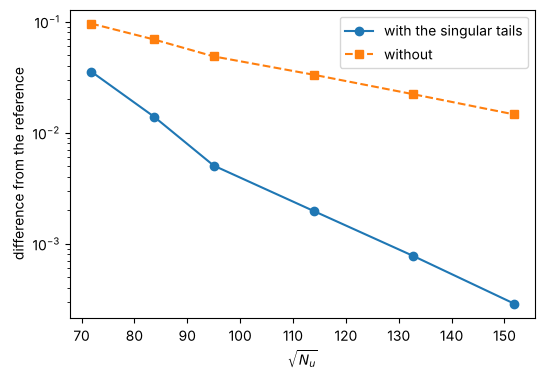

In [4]:
rows = []
for J in range(2, 8):
    E, t, info = cube.solve(J, pts=pts)
    E0 = cube.solve(J, pts=pts, tails=False)[0]
    rows.append((sum(info["unknowns"]) * 4, core.rel(E, ref), core.rel(E0, ref)))
    print(f"J = {J}: {rows[-1][0]:5d} unknowns, error {rows[-1][1]:.1e} (without the tails {rows[-1][2]:.1e}), {t:.1f} s")

rows = np.array(rows)
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(np.sqrt(rows[:, 0]), rows[:, 1], "o-", label="with the singular tails")
ax.semilogy(np.sqrt(rows[:, 0]), rows[:, 2], "s--", label="without")
ax.set(xlabel=r"$\sqrt{N_u}$", ylabel="difference from the reference")
ax.legend()
plt.show()

## Any incident wave
The cube is symmetric under the three mirrors $x \to -x$, $y \to -y$, $z \to -z$, so a wave splits into eight parity classes, each solved on one octant, and under the rotation about the body diagonal, so at most four class matrices are needed. Here is a wave from the polar angle $60^\circ$ and azimuth $25^\circ$, and the total field in the plane $z = 0$.

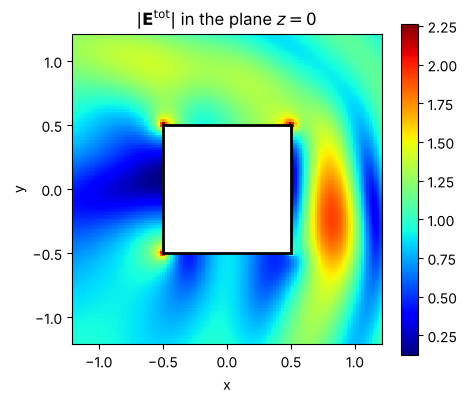

In [5]:
d, p = core.wave(60, 25, 35)
X, Y = np.meshgrid(np.linspace(-1.2, 1.2, 120), np.linspace(-1.2, 1.2, 120))
plane = np.column_stack((X.ravel(), Y.ravel(), 0 * X.ravel()))
outside = np.max(np.abs(plane), axis=1) > 0.5 + 1e-3
E = np.full((len(plane), 3), np.nan, complex)
E[outside] = cube.solve(6, d, p, pts=plane[outside])[0] + core.plane_wave(plane[outside], 2 * np.pi, d, p)

fig, ax = plt.subplots(figsize=(5, 4.3))
im = ax.pcolormesh(X, Y, np.linalg.norm(E, axis=1).reshape(X.shape), cmap="jet", shading="auto")
ax.add_patch(plt.Rectangle((-0.5, -0.5), 1, 1, fill=False, lw=2))
ax.set(aspect="equal", xlabel="x", ylabel="y", title=r"$|\mathbf{E}^{\rm tot}|$ in the plane $z = 0$")
fig.colorbar(im)
plt.show()